# The atmospheric dispersion corrector

The air above a telescope is a prism. It bends the light of a star
towards the zenith by about a minute of arc at 45° from the zenith, and
since its index depends on the wavelength it bends blue light more than
red: away from the zenith every star becomes a short vertical spectrum.
At 60° the blue end of the visible stands more than two arcseconds
above the near infrared at a good site, more than the seeing and a hundred times the
diffraction limit of an 8 m telescope. Spectrographs lose light at their
slits and adaptive optics images are smeared, so large telescopes carry
an *atmospheric dispersion corrector* (ADC): two prisms that add the
opposite dispersion and are turned against each other to follow the
zenith angle.

This notebook uses `pyoptics.adc` for:

1. the index of air after Edlén (Birch and Downs) for the temperature,
   pressure and humidity of a site, against Ciddor's formula,
2. the refraction against the zenith angle: the plane-parallel
   $(n_0-1)\tan z$, the classic $A\tan z - B\tan^3 z$, the exact integral
   of a spherical atmosphere and a ray traced through it as a
   gradient-index medium with `grin.trace()`,
3. the dispersion against the zenith angle and the rainbow-smeared star,
4. the ADC: Amici prisms, a glass pair found in the SCHOTT catalogue to
   follow the dispersion of air, two prisms counter-rotated by $\pm\varphi$,
5. the residual dispersion against the zenith angle, with seeing and with
   adaptive optics.

Example: an 8.2 m telescope on Cerro Paranal (2635 m, 743 hPa, 10 °C,
15 % humidity), the ADC in a collimated beam of 100 mm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import adc
from pyoptics import glasses
from pyoptics import materials
from pyoptics import sketch

t_start = time.time()
ARCSEC = adc.ARCSEC
mas = ARCSEC/1000

## The setup

Left: the light of a star crosses an atmosphere whose index falls off
with height; the ray bends towards the ground, so the star appears
higher than it is, at the apparent zenith angle $z$. Right: the ADC, two
Amici prisms (two glasses of nearly the same index but different
dispersion, cemented with opposed wedges, so that the reference
wavelength passes undeviated). Turned by $+\varphi$ and $-\varphi$ about
the axis their dispersions $\delta$ add to $2\delta\cos\varphi$ along one
direction and cancel across it: from $2\delta$ ($\varphi = 0$) to nothing
($\varphi = 90°$).

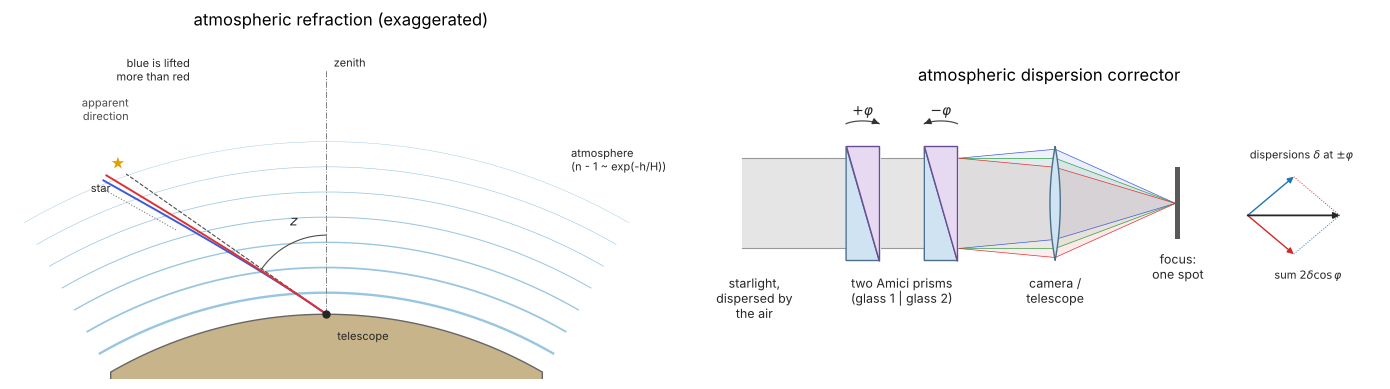

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sketch.adc_layout(axs[0], kind="refraction", title="atmospheric refraction (exaggerated)")
sketch.adc_layout(axs[1], title="atmospheric dispersion corrector")
plt.tight_layout()
plt.show()

## 1. The index of air

Edlén's formula (in the revision of Birch and Downs) gives $n - 1$ for
standard air and scales it with the density, $p/T$ to first order; water
vapour lowers it slightly. For standard air (15 °C, 1013.25 hPa, dry) it
agrees with Ciddor's formula, which `materials.air_index()` uses:

In [3]:
lam = np.array([350.0, 400.0, 500.0, 589.3, 700.0, 900.0, 1000.0])
print("%8s %16s %16s %12s" % ("lambda", "(n-1) Edlen", "(n-1) Ciddor", "difference"))
for l_, a, b in zip(lam, adc.edlen_index(lam) - 1, materials.air_index(lam) - 1):
    print("%8.1f %16.4e %16.4e %12.1e" % (l_, a, b, a - b))
sites = {"sea level, 15 C, dry": (15.0, 101325.0, 0.0),
         "Paranal, 10 C, 743 hPa, 15 %": (10.0, 74300.0, adc.water_vapour_pressure(10.0, 0.15)),
         "Mauna Kea, 0 C, 615 hPa, 20 %": (0.0, 61500.0, adc.water_vapour_pressure(0.0, 0.20))}
print()
print("%32s %14s %22s" % ("", "(n-1) at 550", "n(400) - n(900)"))
for name, (t, p, f) in sites.items():
    n = adc.edlen_index(np.array([400.0, 550.0, 900.0]), t, p, f)
    print("%32s %14.4e %22.3e" % (name, n[1] - 1, n[0] - n[2]))
t_site, p_site, f_site = sites["Paranal, 10 C, 743 hPa, 15 %"]

  lambda      (n-1) Edlen     (n-1) Ciddor   difference
   350.0       2.8612e-04       2.8612e-04     -2.1e-09
   400.0       2.8276e-04       2.8276e-04     -2.6e-09
   500.0       2.7897e-04       2.7897e-04     -2.5e-09
   589.3       2.7715e-04       2.7715e-04     -1.8e-09
   700.0       2.7580e-04       2.7580e-04     -7.1e-10
   900.0       2.7453e-04       2.7453e-04      7.7e-10
  1000.0       2.7417e-04       2.7417e-04      1.3e-09

                                   (n-1) at 550        n(400) - n(900)
            sea level, 15 C, dry     2.7784e-04              8.226e-06
    Paranal, 10 C, 743 hPa, 15 %     2.0725e-04              6.141e-06
   Mauna Kea, 0 C, 615 hPa, 20 %     1.7783e-04              5.269e-06


The two formulas differ by a few $10^{-9}$ (Ciddor assumes slightly more
CO₂), far below anything that matters here. On a high mountain the air is
thinner: at Paranal $n - 1$ is 75 % of its sea level value, on Mauna Kea
64 %, and so are refraction and dispersion. Between 400 and 900 nm the
index changes by $8\cdot10^{-6}$ at sea level, 3 % of $n - 1$.

## 2. Refraction against the zenith angle

In plane parallel layers Snell's law gives $n(h)\sin z(h) = $ const from
the ground to the vacuum, so $\sin z_\mathrm{true} = n_0 \sin z$: the
refraction $R = z_\mathrm{true} - z \approx (n_0 - 1)\tan z$ depends
only on the index at the telescope, not on the profile above. On the
curved Earth the invariant is $n r \sin\psi$ (Bouguer), and for an
isothermal atmosphere ($n - 1 \propto e^{-h/H}$, scale height $H = R_\mathrm{air}T/g
\approx 8.4$ km) the expansion in $\tan z$ is

$$R = A\tan z - B\tan^3 z,\quad A = (n_0-1)(1-\beta),\quad B = (n_0-1)\left(\beta - \frac{n_0-1}{2}\right),\quad \beta = \frac{H}{R_\oplus}.$$

`refraction_integral()` evaluates the exact refraction of this
atmosphere, $R = \int \tan\psi\, dn/n$, and `trace_refraction()` traces the
ray from the telescope up through the atmosphere as a GRIN medium
(`grin.trace()`, Earth radius 6371 km, steps of 50 m up to 150 km):

In [4]:
n0 = adc.edlen_index(550.0)
H = adc.scale_height(15.0)
zdeg = np.array([0, 20, 40, 45, 60, 70, 75, 80, 85.0])
z = np.radians(zdeg)
R_int = adc.refraction_integral(z, n0, H)
R_lap = adc.refraction_laplace(z, n0, H)
R_flat = adc.refraction_flat(z, n0)
t0 = time.time()
R_tr = adc.trace_refraction(z, n0, H, step=50.0)
print("sea level, 15 C, 550 nm, H = %.0f m; trace %.1f s" % (H, time.time() - t0))
print("%6s %12s %12s %14s %12s %12s" % ("z", "integral", "GRIN trace", "A tan - B tan^3",
                                          "(n-1) tan z", "trace-int"))
for k in range(len(z)):
    print("%6.0f %11.3f\" %11.3f\" %13.3f\" %11.3f\" %11.1e\""
          % (zdeg[k], R_int[k]/ARCSEC, R_tr[k]/ARCSEC, R_lap[k]/ARCSEC, R_flat[k]/ARCSEC,
             (R_tr[k] - R_int[k])/ARCSEC))

sea level, 15 C, 550 nm, H = 8434 m; trace 1.9 s
     z     integral   GRIN trace A tan - B tan^3  (n-1) tan z    trace-int
     0       0.000"       0.000"         0.000"       0.000"     0.0e+00"
    20      20.827"      20.827"        20.827"      20.858"    -3.8e-07"
    40      47.984"      47.984"        47.983"      48.087"    -8.7e-07"
    45      57.165"      57.165"        57.164"      57.308"    -1.0e-06"
    60      98.782"      98.782"        98.776"      99.260"    -1.7e-06"
    70     155.882"     155.882"       155.835"     157.452"    -2.5e-06"
    75     210.254"     210.254"       210.062"     213.875"    -3.1e-06"
    80     313.513"     313.513"       312.191"     325.008"    -3.8e-06"
    85     582.285"     582.285"       552.757"     655.030"    -4.5e-06"


The traced rays and the integral agree to a few microarcseconds all the
way down to 85°: the GRIN tracer solves the same problem. At 45° the
refraction is the classic 57″ at sea level. The two term formula is good
to 0.01″ down to 60° (0.05″ at 70°) and fails near the horizon, where $\tan z$ diverges
while the true refraction (about 35′ at the horizon) stays finite; the
plane parallel formula is already 0.5″ off at 60°.

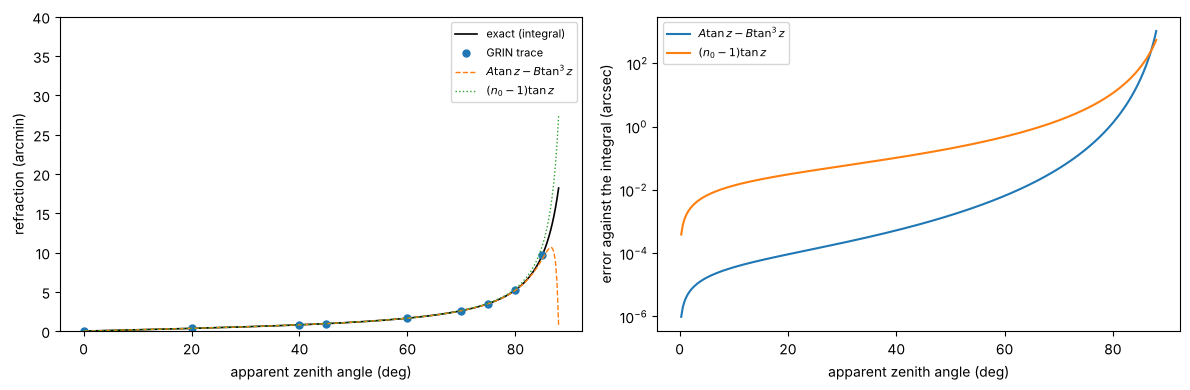

In [5]:
zz = np.radians(np.linspace(0, 88, 300))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
Ri = adc.refraction_integral(zz, n0, H)
axs[0].plot(np.degrees(zz), Ri/ARCSEC/60, "k-", lw=1.2, label="exact (integral)")
axs[0].plot(zdeg, R_tr/ARCSEC/60, "o", ms=5, label="GRIN trace")
axs[0].plot(np.degrees(zz), adc.refraction_laplace(zz, n0, H)/ARCSEC/60, "--", lw=1,
            label=r"$A\tan z - B\tan^3 z$")
axs[0].plot(np.degrees(zz), adc.refraction_flat(zz, n0)/ARCSEC/60, ":", lw=1,
            label=r"$(n_0-1)\tan z$")
axs[0].set_ylim(0, 40)
axs[0].set_xlabel("apparent zenith angle (deg)")
axs[0].set_ylabel("refraction (arcmin)")
axs[0].legend(fontsize=8)
err_lap = np.abs(adc.refraction_laplace(zz[1:], n0, H) - Ri[1:])/ARCSEC
err_flat = np.abs(adc.refraction_flat(zz[1:], n0) - Ri[1:])/ARCSEC
axs[1].semilogy(np.degrees(zz[1:]), err_lap, label=r"$A\tan z - B\tan^3 z$")
axs[1].semilogy(np.degrees(zz[1:]), err_flat, label=r"$(n_0-1)\tan z$")
axs[1].set_xlabel("apparent zenith angle (deg)")
axs[1].set_ylabel("error against the integral (arcsec)")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Dispersion and the rainbow star

Relative to a reference wavelength the refraction differs by
$(n(\lambda) - n(\lambda_\mathrm{ref}))\tan z\,(1 - \beta)$ to first order: the dispersion grows
like $\tan z$, and is largest in the blue, where $n$ changes fastest. At
Paranal, relative to 550 nm:

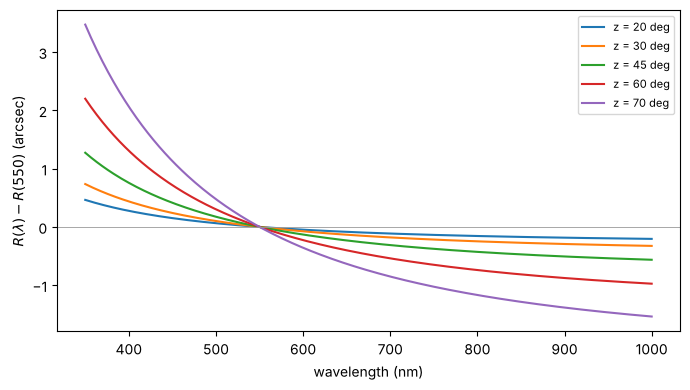

length of the 400-900 nm spectrum at Paranal (arcsec):
  z = 20 deg (airmass 1.06): 0.460" (exact integral 0.460")
  z = 30 deg (airmass 1.15): 0.730" (exact integral 0.730")
  z = 45 deg (airmass 1.41): 1.264" (exact integral 1.264")
  z = 60 deg (airmass 2.00): 2.184" (exact integral 2.184")
  z = 70 deg (airmass 2.92): 3.447" (exact integral 3.448")


In [6]:
lam = np.linspace(350, 1000, 300)
fig, ax = plt.subplots(figsize=(7, 4))
for zd in (20, 30, 45, 60, 70):
    dR = adc.atmospheric_dispersion(lam, np.radians(zd), 550.0, t_site, p_site, f_site)
    ax.plot(lam, dR/ARCSEC, label="z = %d deg" % zd)
ax.axhline(0, color="0.6", lw=0.6)
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel(r"$R(\lambda) - R(550)$ (arcsec)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
band = np.linspace(400, 900, 51)
print("length of the 400-900 nm spectrum at Paranal (arcsec):")
for zd in (20, 30, 45, 60, 70):
    zr = np.radians(zd)
    dR = adc.atmospheric_dispersion(band, zr, 550.0, t_site, p_site, f_site)
    dR_ex = adc.atmospheric_dispersion(np.array([400.0, 900.0]), zr, 550.0, t_site, p_site, f_site,
                                       exact=True)
    print("  z = %2d deg (airmass %.2f): %.3f\" (exact integral %.3f\")"
          % (zd, 1/np.cos(zr), (dR[0] - dR[-1])/ARCSEC, (dR_ex[0] - dR_ex[1])/ARCSEC))

At 60° the 400 to 900 nm spectrum spreads over 2.2″, three times as
much as at 30° and almost four times the seeing. The image of a star is the
sum of its monochromatic images, each displaced by $R(\lambda)$. With
0.6″ seeing (left two rows) and with the diffraction limit of an 8.2 m
telescope with adaptive optics (a Gaussian of FWHM $\lambda/D$, right),
for a sunlike star and a flat detector response from 400 to 900 nm:

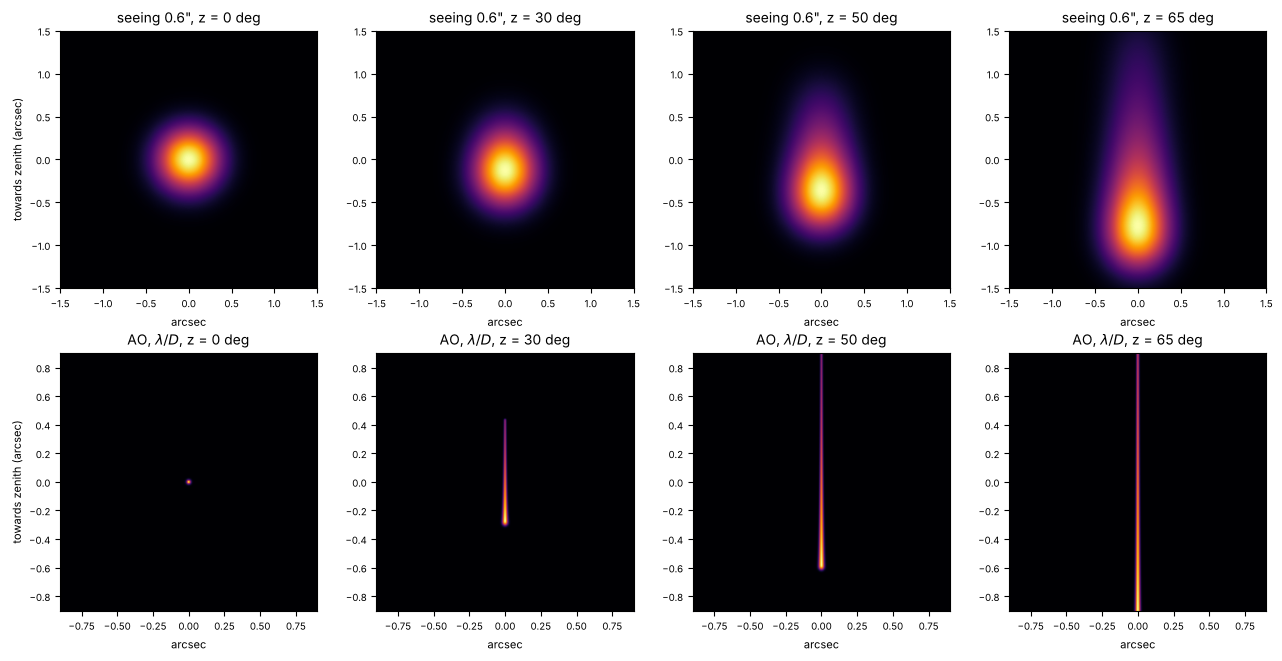

In [7]:
hc_k = 1.4387769e7
photons = band**-4/np.expm1(hc_k/(band*5800.0))          # photons per nm
weights = photons/photons.sum()
band_f = np.linspace(400, 900, 1001)                      # fine sampling for the images
w_f = band_f**-4/np.expm1(hc_k/(band_f*5800.0))
w_f /= w_f.sum()
D_tel = 8.2
x = np.linspace(-1.5, 1.5, 241)                           # arcsec
xa = np.linspace(-0.9, 0.9, 361)
fig, axs = plt.subplots(2, 4, figsize=(13, 6.6))
for k, zd in enumerate((0, 30, 50, 65)):
    dR = adc.atmospheric_dispersion(band_f, np.radians(zd), 550.0, t_site, p_site, f_site)/ARCSEC
    img = adc.smeared_star(x, x, band_f, w_f, dR, 0.6)
    axs[0, k].imshow(img, extent=(x[0], x[-1], x[0], x[-1]), origin="lower", cmap="inferno")
    axs[0, k].set_title("seeing 0.6\", z = %d deg" % zd, fontsize=10)
    fwhm = band_f*1e-9/D_tel/ARCSEC
    img = adc.smeared_star(xa, xa, band_f, w_f, dR, fwhm)
    axs[1, k].imshow(img**0.5, extent=(xa[0], xa[-1], xa[0], xa[-1]), origin="lower", cmap="inferno")
    axs[1, k].set_title(r"AO, $\lambda/D$, z = %d deg" % zd, fontsize=10)
for a in axs.flat:
    a.set_xlabel("arcsec", fontsize=8)
    a.tick_params(labelsize=7)
axs[0, 0].set_ylabel("towards zenith (arcsec)", fontsize=8)
axs[1, 0].set_ylabel("towards zenith (arcsec)", fontsize=8)
plt.tight_layout()
plt.show()

With seeing the star becomes an elongated, blue-topped blob; with
adaptive optics (bottom, square root of the intensity) a 15 mas image
turns into a streak more than a hundred times longer. A slit spectrograph aligned
across the dispersion would see the colours of the star enter different
parts of the slit, or miss it.

## 4. The ADC

### Amici prisms

A thin prism of apex angle $\alpha$ deviates by $(n-1)\alpha$. An Amici
prism cements two thin prisms of glasses 1 and 2 with opposed wedges, so
it deviates by $(n_1 - n_2)\alpha$: almost nothing if the indices are
close, but with a dispersion $(n_1(\lambda) - n_2(\lambda))\alpha$. The ADC cancels the
atmosphere at all wavelengths only if this difference has the shape of
$n_\mathrm{air}(\lambda)$, i.e. if the glass pair has the *relative partial
dispersion* of air. `best_glass_pairs()` searches the SCHOTT catalogue
(standard and preferred glasses) for pairs whose index difference
follows the air dispersion between 400 and 900 nm, with matched indices
($|n_1 - n_2| < 0.01$) and a dispersion difference at least 1000 times
that of air (otherwise the prisms get too steep):

In [8]:
cat = glasses.catalog("schott", status=("standard", "preferred"))
best = adc.best_glass_pairs(cat, band, 550.0, max_delta_n=0.01, min_scale=1000, k=6,
                            t=t_site, p=p_site, f=f_site)
print("%10s %12s %12s %12s %10s" % ("rel. rms", "glass 1", "glass 2", "scale", "n1 - n2"))
for rel, g1, g2, scale, dn in best:
    print("%10.4f %12s %12s %12.0f %10.4f" % (rel, g1, g2, scale, dn))
naive = adc.best_glass_pairs({"N-F2": glasses.get("N-F2"), "N-BK7": glasses.get("N-BK7")}, band,
                             550.0, max_delta_n=1.0, k=1, t=t_site, p=p_site, f=f_site)[0]
print("%10.4f %12s %12s %12.0f %10.4f   (a flint and a crown)" % naive)

  rel. rms      glass 1      glass 2        scale    n1 - n2
    0.0175        N-KF9       N-PK51         1457    -0.0044
    0.0197          K10      N-PK52A         1241     0.0050
    0.0227    N-KZFS4HT      N-SK2HT         1367     0.0066
    0.0227      N-KZFS4        N-SK2         1367     0.0066
    0.0227    N-KZFS4HT        N-SK2         1367     0.0066
    0.0227      N-KZFS4      N-SK2HT         1367     0.0066
    0.0602         N-F2        N-BK7         3963     0.1051   (a flint and a crown)


The best pair, the light flint N-KF9 with the phosphate crown N-PK51,
follows the shape of the air dispersion to 1.8 % rms; a flint and a crown
like N-F2 and N-BK7, almost three times as dispersive, only to 6 %, because
flints disperse relatively more in the blue than air does (and their
indices differ by 0.1, which would deviate the beam). The two shapes:

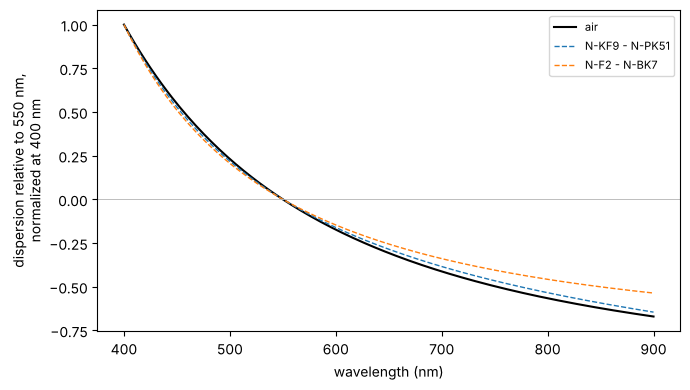

In [9]:
lam_p = np.linspace(400, 900, 200)
air = adc.edlen_index(lam_p, t_site, p_site, f_site) - adc.edlen_index(550.0, t_site, p_site, f_site)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lam_p, air/air[0], "k-", lw=1.5, label="air")
for g1, g2 in (("N-KF9", "N-PK51"), ("N-F2", "N-BK7")):
    a, b = glasses.get(g1), glasses.get(g2)
    d = (a(lam_p) - b(lam_p)) - (a(550.0) - b(550.0))
    ax.plot(lam_p, d/d[0], "--", lw=1, label="%s - %s" % (g1, g2))
ax.axhline(0, color="0.7", lw=0.6)
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("dispersion relative to 550 nm,\nnormalized at 400 nm")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Sizing the prisms

In a collimated beam reduced from $D_\mathrm{tel}$ to $D_\mathrm{beam}$ the angles
grow by $M = D_\mathrm{tel}/D_\mathrm{beam}$, so a deviation $\delta$ in the beam is
$\delta/M$ on the sky. To cancel the dispersion up to $z_\mathrm{max} = 60°$ with
$\varphi = 0$ the apex angle must be

$$\alpha = \frac{M\tan z_\mathrm{max}(1-\beta)}{2\,s},$$

with the scale $s$ of the pair from the table (its index difference
disperses $s$ times as much as air). The thin prism formula against the
exact deviation of the thick Amici prism:

In [10]:
M = D_tel/0.1
z_max = np.radians(60.0)
g1, g2 = glasses.get("N-KF9"), glasses.get("N-PK51")
scale = best[0][3]
beta = adc.scale_height(t_site)/adc.R_EARTH
apex = M*np.tan(z_max)*(1 - beta)/(2*scale)
prism = adc.AmiciPrism(g1, g2, apex)
print("M = %.0f, apex angle %.2f deg" % (M, np.degrees(apex)))
print("%8s %16s %16s" % ("lambda", "thin (arcsec)", "exact (arcsec)"))
for l_ in (400.0, 550.0, 700.0, 900.0):
    print("%8.0f %16.3f %16.3f" % (l_, prism.deviation(l_)/ARCSEC, prism.deviation_exact(l_)/ARCSEC))
d_ref = prism.deviation(550.0)
print("deviation of 550 nm by both prisms at phi = 0: %.1f arcsec in the beam, %.2f arcsec on the sky"
      % (2*d_ref/ARCSEC, 2*d_ref/M/ARCSEC))

M = 82, apex angle 2.79 deg
  lambda    thin (arcsec)   exact (arcsec)
     400           11.665           11.674
     550          -44.176          -44.210
     700          -65.648          -65.699
     900          -80.223          -80.286
deviation of 550 nm by both prisms at phi = 0: -88.4 arcsec in the beam, -1.08 arcsec on the sky


An apex of 2.8° is enough. The thin prism formula is good to 0.1 % (the
exact deviation is slightly larger). The indices of N-KF9 and N-PK51
differ by 0.004, so the prisms also deviate the beam, by up to 1″ on the
sky, an amount that changes with $\varphi$; the telescope's guider takes this out, and in
practice a third, fixed wedge or a slightly different pair can null it.

## 5. The residual against the zenith angle

For every zenith angle `adc_residual()` turns the prisms to the angle
$\varphi$ that best cancels the atmosphere over the band (weighted with
the photons of the star) and returns what is left:

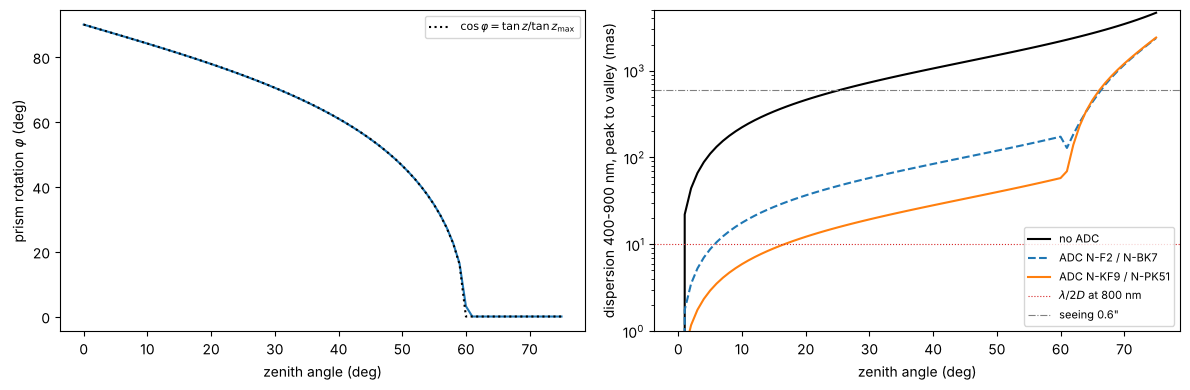

z = 30 deg: phi =  70.5 deg, dispersion    730 mas ->  19.4 mas (flint/crown  58.1 mas)
z = 45 deg: phi =  54.7 deg, dispersion   1264 mas ->  33.5 mas (flint/crown 100.5 mas)
z = 60 deg: phi =   3.2 deg, dispersion   2184 mas ->  57.9 mas (flint/crown 173.7 mas)
z = 70 deg: phi =   0.0 deg, dispersion   3447 mas -> 1206.0 mas (flint/crown 1172.6 mas)


In [11]:
zds = np.linspace(0, 75, 76)
phis, res_rms, res_pv, raw_pv = [], [], [], []
naive_prism = adc.AmiciPrism(glasses.get("N-F2"), glasses.get("N-BK7"),
                             M*np.tan(z_max)*(1 - beta)/(2*naive[3]))
naive_pv = []
for zd in zds:
    dR = adc.atmospheric_dispersion(band, np.radians(zd), 550.0, t_site, p_site, f_site)
    phi, res = adc.adc_residual(prism, band, dR, M, 550.0, weights)
    _, res_n = adc.adc_residual(naive_prism, band, dR, M, 550.0, weights)
    phis.append(phi)
    res_pv.append(np.ptp(res))
    naive_pv.append(np.ptp(res_n))
    raw_pv.append(np.ptp(dR))
phis = np.degrees(phis)
res_pv, naive_pv, raw_pv = np.array(res_pv), np.array(naive_pv), np.array(raw_pv)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(zds, phis)
axs[0].plot(zds, np.degrees(np.arccos(np.clip(np.tan(np.radians(zds))/np.tan(z_max), 0, 1))), "k:",
            label=r"$\cos\varphi = \tan z/\tan z_\mathrm{max}$")
axs[0].set_xlabel("zenith angle (deg)")
axs[0].set_ylabel(r"prism rotation $\varphi$ (deg)")
axs[0].legend(fontsize=8)
axs[1].semilogy(zds, raw_pv/mas, "k-", label="no ADC")
axs[1].semilogy(zds, naive_pv/mas, "--", label="ADC N-F2 / N-BK7")
axs[1].semilogy(zds, res_pv/mas, "-", label="ADC N-KF9 / N-PK51")
axs[1].axhline(1e3*800e-9/D_tel/ARCSEC/2, color="C3", ls=":", lw=0.8, label=r"$\lambda/2D$ at 800 nm")
axs[1].axhline(600, color="0.5", ls="-.", lw=0.8, label="seeing 0.6\"")
axs[1].set_xlabel("zenith angle (deg)")
axs[1].set_ylabel("dispersion 400-900 nm, peak to valley (mas)")
axs[1].set_ylim(1, 5e3)
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
for zd in (30, 45, 60, 70):
    k = np.argmin(np.abs(zds - zd))
    print("z = %2d deg: phi = %5.1f deg, dispersion %6.0f mas -> %5.1f mas (flint/crown %5.1f mas)"
          % (zd, phis[k], raw_pv[k]/mas, res_pv[k]/mas, naive_pv[k]/mas))

The prism angle follows $\cos\varphi = \tan z/\tan z_\mathrm{max}$ (the atmosphere
grows as $\tan z$, the ADC as $\cos\varphi$). Up to 60° the matched pair
reduces the 400 to 900 nm spread to under 3 % of the original, 58 mas at
60°: far below the seeing, though still several times the diffraction
limit of adaptive optics; the flint/crown pair leaves three times more. Beyond
$z_\mathrm{max}$ the ADC is at full strength and the residual grows
with the uncorrected rest.

The corrected images at 60°:

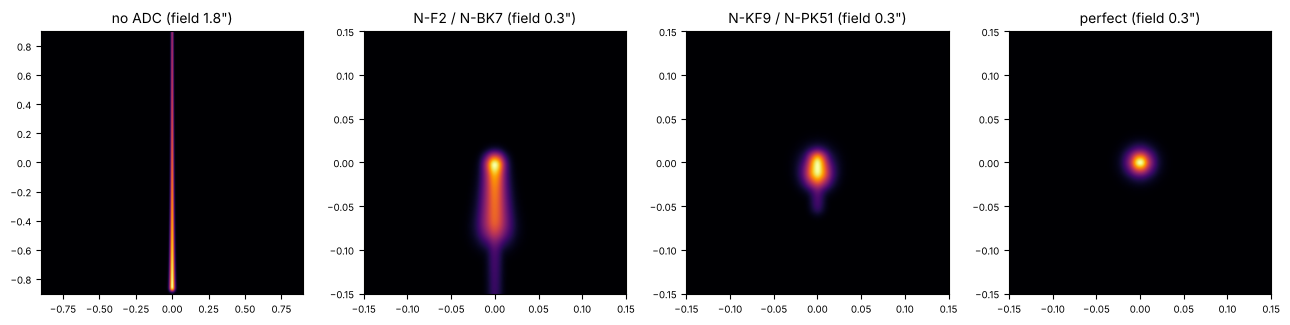

peak intensity relative to perfect correction: flint/crown 0.30, matched pair 0.52


In [12]:
zr = np.radians(60.0)
dR = adc.atmospheric_dispersion(band_f, zr, 550.0, t_site, p_site, f_site)
phi, res = adc.adc_residual(prism, band_f, dR, M, 550.0, w_f)
_, res_n = adc.adc_residual(naive_prism, band_f, dR, M, 550.0, w_f)
fwhm = band_f*1e-9/D_tel/ARCSEC
xs = np.linspace(-0.15, 0.15, 241)
fig, axs = plt.subplots(1, 4, figsize=(13, 3.6))
img = adc.smeared_star(xa, xa, band_f, w_f, dR/ARCSEC, fwhm)
axs[0].imshow(img**0.5, extent=(xa[0], xa[-1], xa[0], xa[-1]), origin="lower", cmap="inferno")
axs[0].set_title("no ADC (field 1.8\")", fontsize=10)
peaks = []
for a, r_, name in ((axs[1], res_n, "N-F2 / N-BK7"), (axs[2], res, "N-KF9 / N-PK51"),
                    (axs[3], 0*res, "perfect")):
    img = adc.smeared_star(xs, xs, band_f, w_f, r_/ARCSEC, fwhm)
    peaks.append(img.max())
    a.imshow(img**0.5, extent=(xs[0], xs[-1], xs[0], xs[-1]), origin="lower", cmap="inferno")
    a.set_title("%s (field 0.3\")" % name, fontsize=10)
for a in axs:
    a.tick_params(labelsize=7)
plt.tight_layout()
plt.show()
print("peak intensity relative to perfect correction: flint/crown %.2f, matched pair %.2f"
      % (peaks[0]/peaks[2], peaks[1]/peaks[2]))

At the diffraction limit of an 8 m telescope (15 mas at 600 nm) the
residual of a few tens of milliarcseconds is still visible: the matched
pair keeps about half of the peak intensity of a perfect correction, the
flint/crown pair about a third. Real ADCs for adaptive optics use three
glasses or narrower bands; for seeing limited instruments a two-glass
ADC is ample.

## Summary

- The index of air (Edlén / Birch and Downs, or Ciddor) gives the
  refraction: $(n_0 - 1)\tan z$ in plane layers, $A\tan z - B\tan^3 z$
  on the curved Earth, the exact integral and a GRIN ray trace agreeing to
  microarcseconds; about 1′ at 45° at sea level, 3/4 of that at Paranal.
- The dispersion grows as $\tan z$; at 60° the 400 to 900 nm spectrum of
  a star is 2.2″ long at Paranal, almost four times the seeing.
- An ADC of two Amici prisms counter-rotated by $\pm\varphi$ gives
  $2\delta\cos\varphi$; with a glass pair whose index difference follows the
  air dispersion (N-KF9 / N-PK51 from the SCHOTT catalogue) it leaves a
  58 mas of the 2.2″ at 60°, three times less than a flint and a crown.

## References

- B. Edlén, "The refractive index of air", Metrologia 2, 71–80 (1966).
- K. P. Birch and M. J. Downs, "An updated Edlén equation for the
  refractive index of air", Metrologia 30, 155–162 (1993), and correction,
  Metrologia 31, 315–316 (1994).
- P. E. Ciddor, "Refractive index of air: new equations for the visible
  and near infrared", Appl. Opt. 35, 1566–1573 (1996).
- R. M. Green, *Spherical Astronomy*, Cambridge University Press (1985),
  chapter 4.
- A. V. Filippenko, "The importance of atmospheric differential
  refraction in spectrophotometry", Publ. Astron. Soc. Pac. 94, 715–721
  (1982).
- C. G. Wynne and S. P. Worswick, "Atmospheric dispersion correctors at
  the Cassegrain focus", Mon. Not. R. Astron. Soc. 220, 657–670 (1986).

In [13]:
print("notebook run time %.0f s" % (time.time() - t_start))

notebook run time 12 s
